# Spatial Big Data with DuckDB

用空间SQL查询全国两周微博，汇总位置网格与城市间观测联系，再用Lonboard绘制网格地图和有向联系网络。

<a id="course-toc"></a>
**目录**

- [1 把空间操作放进查询](#section-1)
- [2 连接DuckDB并加载Spatial](#section-2)
- [3 直接读Parquet：先过滤，再构造点](#section-3)
  - [3.1 矩形窗口：先限定研究范围](#section-3-1)
- [4 空间连接：哪些点在分析圆内？](#section-4)
  - [4.1 用同一个参考点重现04的范围查询](#section-4-1)
  - [4.2 查询计划：空间关系怎样被执行？](#section-4-2)
  - [4.3 行政边界：用空间SQL汇总市州](#section-4-3)
- [5 全国空间汇总：先计算，再传给绘图](#section-5)
  - [5.1 WKB → GeoPandas → Lonboard](#section-5-1)
- [6 Lonboard：更多网格面与高德底图](#section-6)
  - [6.1 网格面与比例圆点怎样选择？](#section-6-1)
  - [6.2 用SQL改变空间分辨率](#section-6-2)
- [7 城市间观测联系：从用户时序到有向网络](#section-7)
  - [7.1 先核对观测时刻与城市](#section-7-1)
  - [7.2 LAG：找到同一用户的上一条观测](#section-7-2)
  - [7.3 构建城市节点与加权边](#section-7-3)
  - [7.4 节点的入向与出向联系](#section-7-4)
  - [7.5 ArcLayer：把城市联系画在高德底图上](#section-7-5)
  - [7.6 时间间隔阈值会改变哪些结果？](#section-7-6)
- [8 从查询到索引](#section-8)
  - [8.1 R-tree适合什么查询？](#section-8-1)
- [9 综合练习](#section-9)
  - [9.1 改变范围与分组](#section-9-1)
  - [9.2 让空间条件与文本条件一起工作](#section-9-2)
  - [9.3 开放问题：百万点一定要全画吗？](#section-9-3)

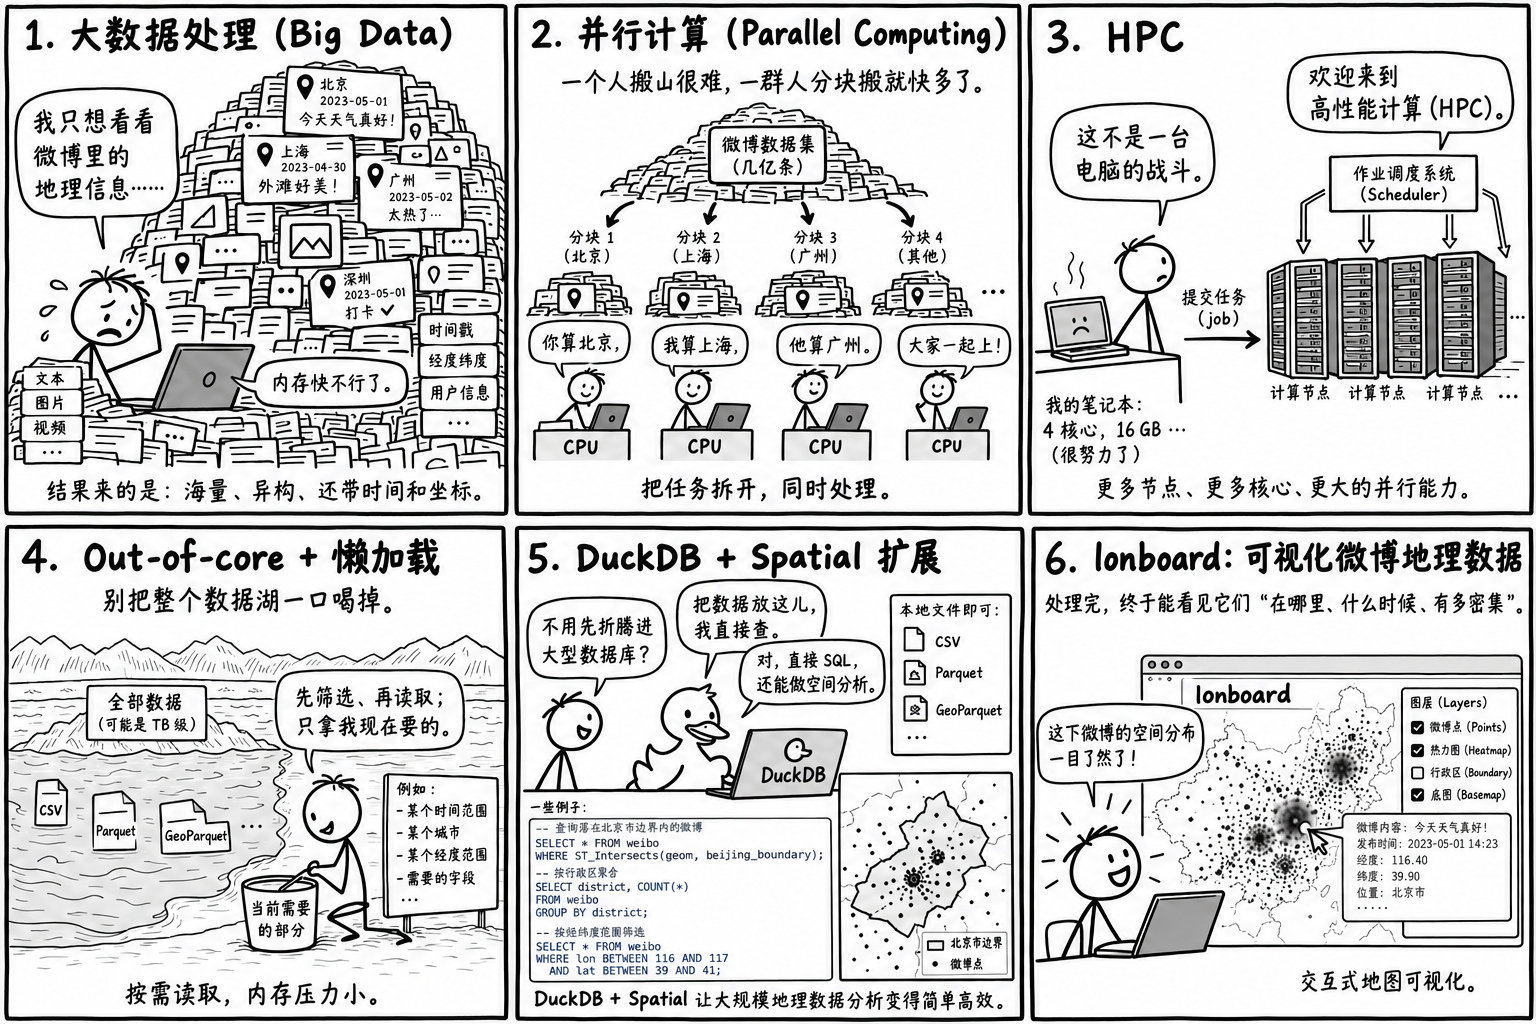

<a id="section-1"></a>
## 1 把空间操作放进查询 **[重点]**

从全国两周Parquet查询空间数据。本节有两条相连的分析线：

1. 空间范围与网格：过滤位置 → 查询分析圆与行政范围 → 汇总网格 → 绘制地图。
2. 城市间观测联系：按用户和时刻排序 → 比较相邻城市 → 汇总有向边 → 绘制城市网络。

DuckDB完成记录级筛选、排序和汇总，Lonboard接收较小的结果表。这里的观测期为2022年8月12—25日，使用同一份全国数据。

记住：这些是GCJ-02网格中心和离散记录。地图与同坐标行政面直接使用原数值；米制测量先近似转WGS84再投影。城市间的相邻观测也不等于完整出行轨迹。

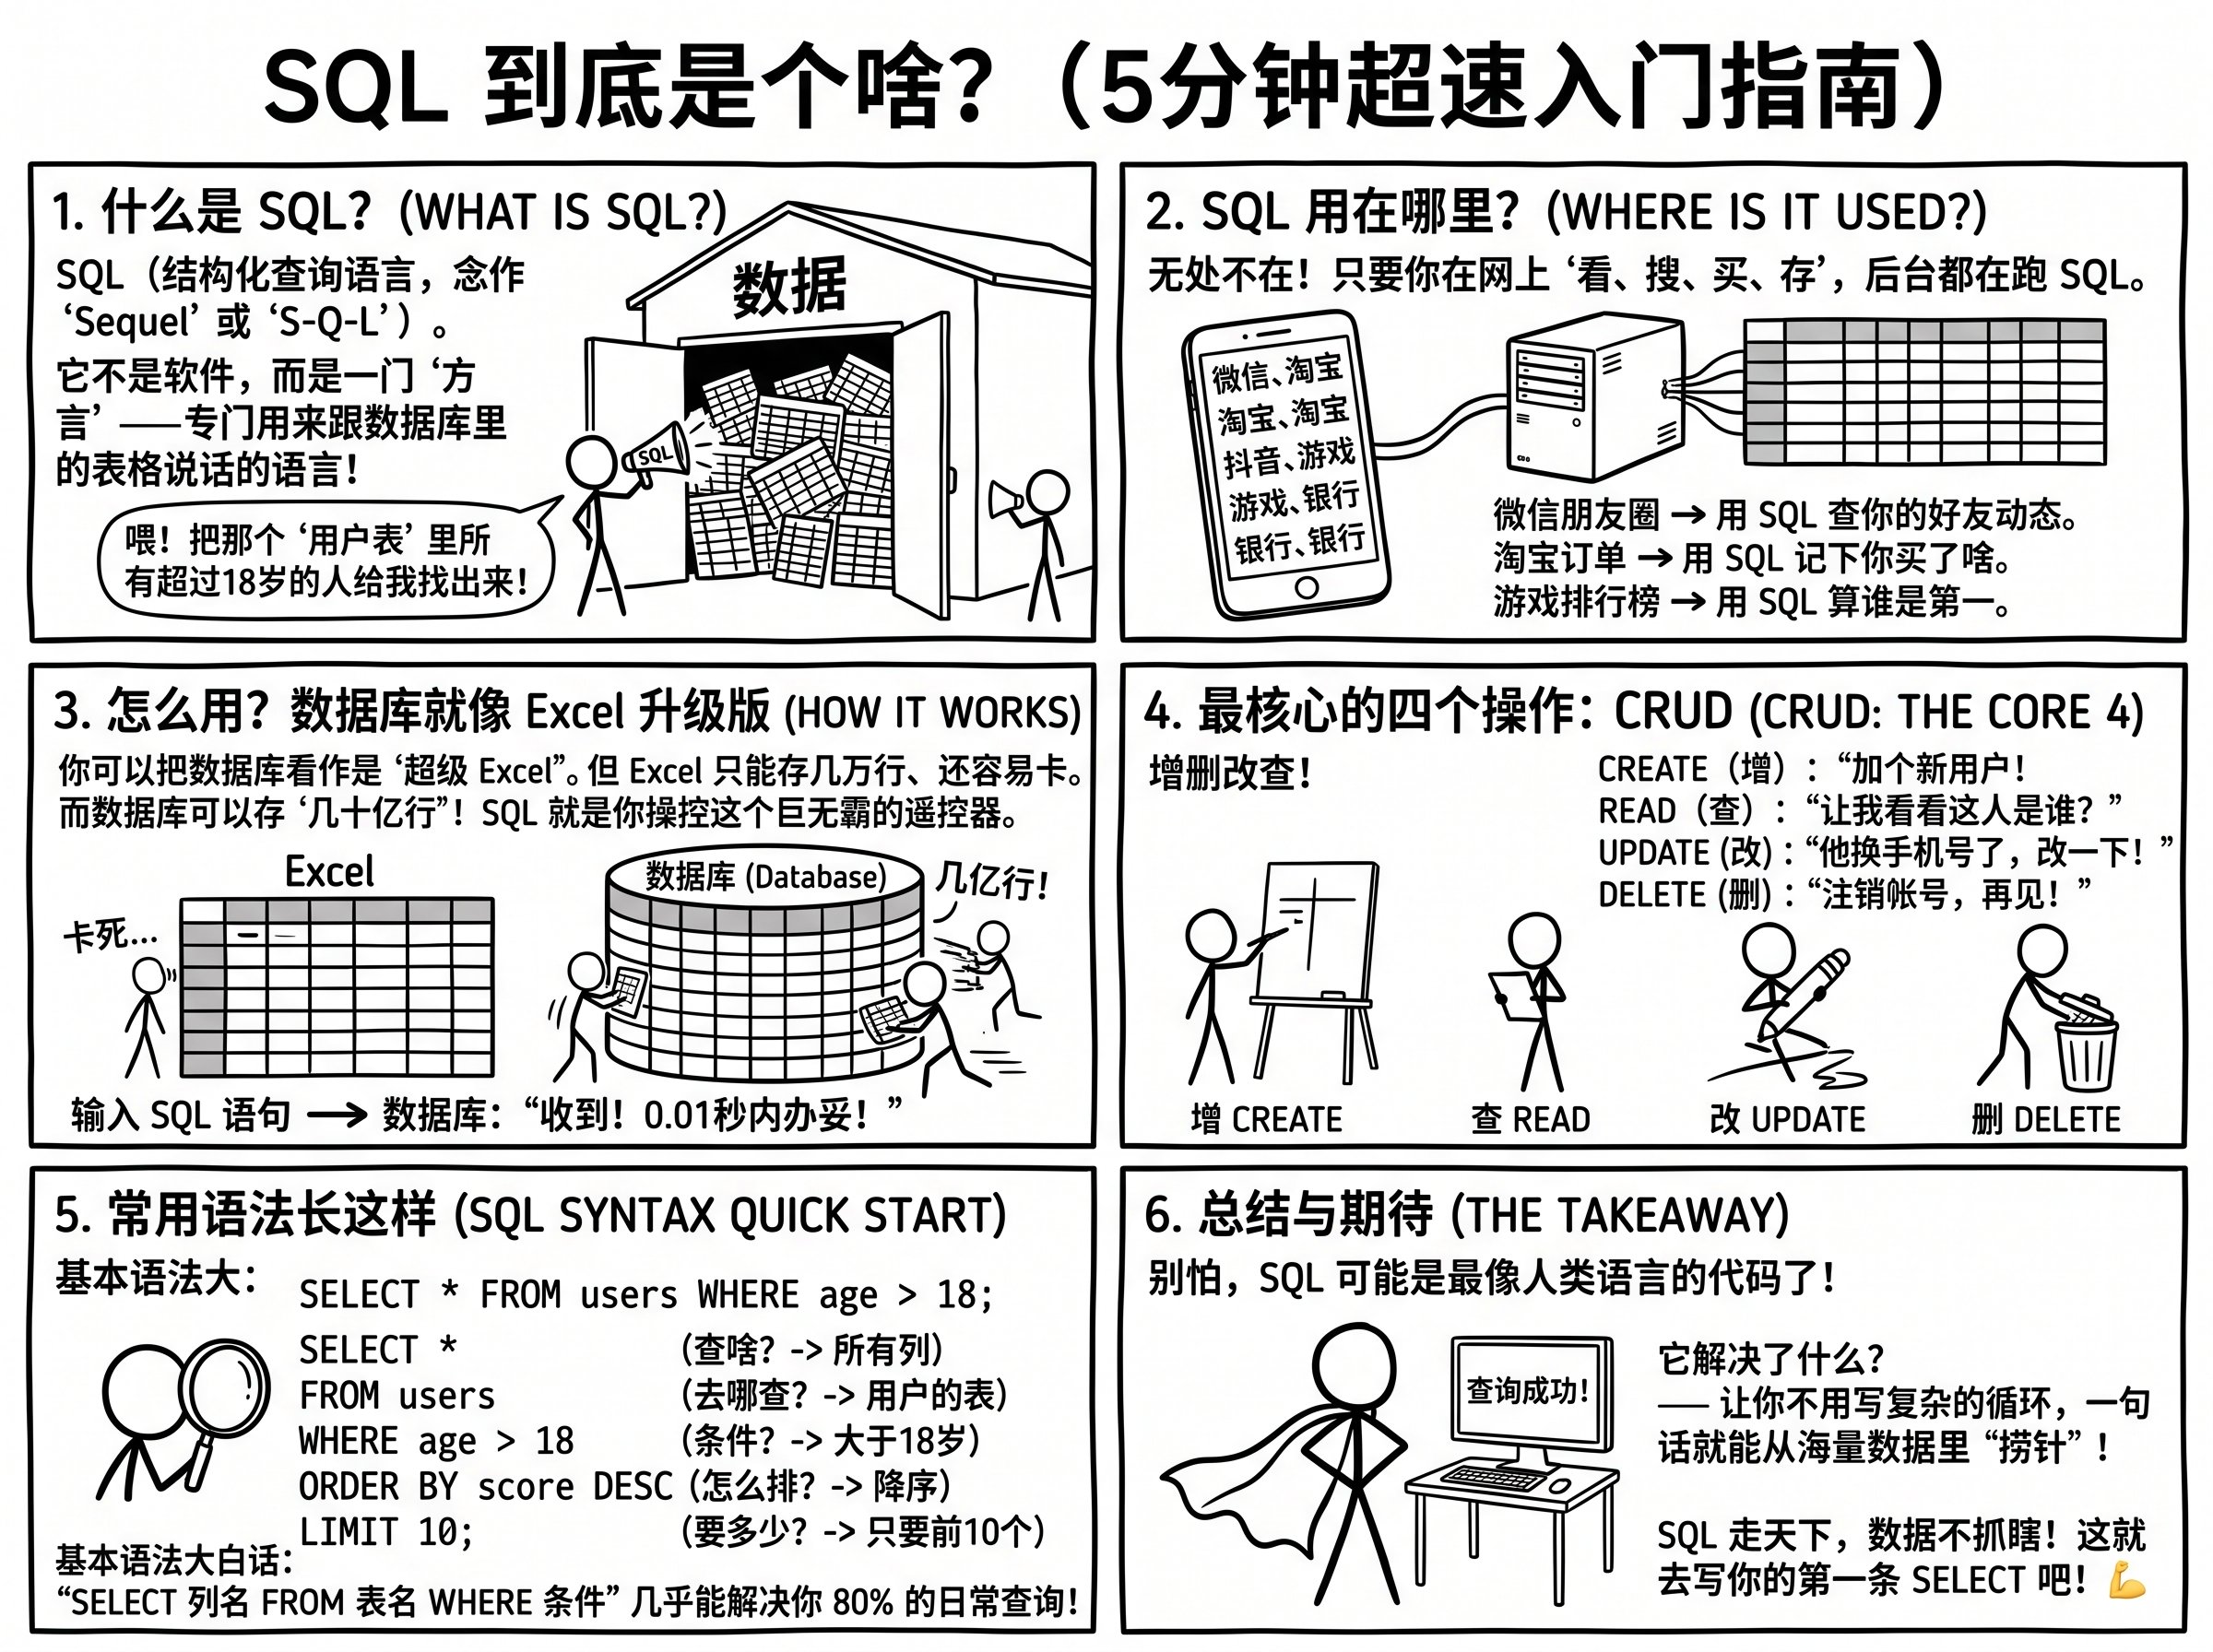

In [ ]:
# 保持整个tutorials文件夹结构；支持从项目根目录或tutorials目录启动。
from pathlib import Path
TUTORIAL_DIR = Path('.') if Path('data/posts_two_weeks.parquet').is_file() else Path('tutorials')
DATA = TUTORIAL_DIR / 'data/posts_two_weeks.parquet'
assert DATA.is_file(), '请先完整解压课堂资料，并用VS Code打开包含tutorials的文件夹'

<a id="section-2"></a>
## 2 连接DuckDB并加载Spatial **[重点]**

DuckDB负责读取、筛选和聚合；Spatial扩展增加点、线、面及空间关系函数。`INSTALL spatial`首次下载与DuckDB版本匹配的扩展，`LOAD spatial`在当前连接启用它。首次安装需要联网，之后使用本机缓存。

沿用03的JupySQL：`%%sql`交给同一个Python内核中的DuckDB连接执行。SQL单元设置为SQL高亮；不要把整个Notebook换成SQL Server内核。

连接中的表保存在内存里。重跑连接单元会沿用仍打开的连接；**重启内核或关闭连接后，旧的输出表格可能仍显示，但数据库中的表需要重新创建**。此时使用“全部运行”，或从头依次执行相关单元，不能只运行最后的地图。

In [ ]:
# 连接创建时才导入DuckDB；重跑本格时保留仍打开的连接和内存表。
import duckdb
try:
    con.execute('SELECT 1')
except (NameError, duckdb.ConnectionException):
    con = duckdb.connect()
%load_ext sql
# 将当前con交给JupySQL，避免SQL与Python使用不同的连接。
%sql con --alias spatial
# 文件路径进入SQL前使用正斜杠，并转义路径中的单引号。
PARQUET_PATH = DATA.as_posix().replace("'", "''")


In [ ]:
%%sql
-- 首次安装需要联网；扩展与当前DuckDB版本对应。
INSTALL spatial;
LOAD spatial;
-- 验证一个点；ST_Point按经度、纬度顺序接收坐标。
SELECT ST_AsText(ST_Point(104.07, 30.67)) AS example_point;

<a id="section-3"></a>
## 3 直接读Parquet：先过滤，再构造点 **[重点]**

视图保存查询逻辑，不提前把整张全国表读成Pandas对象。只保留需要的列与可用位置记录，再用`ST_Point`构造几何。

`GEOMETRY`保存几何形状；在当前1.4版示范中，不能因为列名叫geom就认为它自动带有已核实的CRS。投影转换时仍明确写出源、目标坐标系。

保留`created_at`供后面的用户时序分析；`date`用于按日汇总，不能用它替代同一天内的发帖时刻。

In [ ]:
%%time
%%sql
-- 视图不复制整个文件；查询时才读取和计算。
CREATE OR REPLACE VIEW located AS
SELECT post_id, user_id, created_at, date::DATE AS date, city_code, city, province_code,
       longitude_grid, latitude_grid,
       ST_Point(longitude_grid, latitude_grid) AS geom
FROM read_parquet('{{PARQUET_PATH}}')
WHERE usable_text AND coordinate_valid;
-- 检查实际记录量，不预填一个“大数据”的固定门槛。
SELECT count(*) AS located_records, count(DISTINCT user_id) AS users,
       min(date) AS first_date, max(date) AS last_date FROM located;

<a id="section-3-1"></a>
### 3.1 矩形窗口：先限定研究范围

`ST_MakeEnvelope(最小经度, 最小纬度, 最大经度, 最大纬度)`构造矩形；`ST_Intersects`判断点是否与矩形相交，边界上的点也计入。

下面只是成都附近的教学矩形，不是成都市行政边界。用城市字段筛选与用几何范围筛选，是两个不同问题。

In [ ]:
%%sql
SELECT city, count(*) AS n_posts, count(DISTINCT user_id) AS n_users
FROM located
WHERE ST_Intersects(geom, ST_MakeEnvelope(103.7, 30.3, 104.5, 31.0))
GROUP BY city
ORDER BY n_posts DESC;

<a id="section-4"></a>
## 4 空间连接：哪些点在分析圆内？ **[重点]**

与04一样，GCJ-02原始坐标不能直接以EPSG:4326传给`ST_Transform`。先仅取成都不重复的网格中心，用`gcj2wgs`近似转换一次，再按原网格键连接回记录；这比对每条重复帖子转换更直观，也避免在SQL里写复杂坐标公式。

`geom`保留GCJ-02，供同坐标的矩形及行政边界查询；`geom_m`来自转换后的WGS84点，再投影到UTM 48N（EPSG:32648），用于距离。`always_xy := true`明确轴顺序。

物化的成都表留在当前内存数据库，关闭连接后释放；全国Parquet仍保留在磁盘。

In [ ]:
# 只转换成都的不同网格中心，不把全国帖子读入Pandas。
from xyconvert import gcj2wgs
city_coords = con.execute("""
    SELECT DISTINCT longitude_grid, latitude_grid FROM located
    WHERE province_code='51' AND city_code='5101'
""").fetchdf()
xy_wgs = gcj2wgs(city_coords[['longitude_grid', 'latitude_grid']].to_numpy())
city_coords['wgs_lon'] = xy_wgs[:, 0]
city_coords['wgs_lat'] = xy_wgs[:, 1]
# register让SQL读取小型Python表，原始Parquet和GCJ-02字段保持不变。
con.register('city_coords', city_coords)
city_coords.head()

In [ ]:
%%sql
CREATE OR REPLACE TABLE city_points AS
SELECT p.post_id, p.user_id, p.date, p.geom,
       ST_Transform(ST_Point(c.wgs_lon, c.wgs_lat), 'EPSG:4326', 'EPSG:32648',
                    always_xy := true) AS geom_m
FROM located p JOIN city_coords c USING (longitude_grid, latitude_grid)
WHERE p.province_code = '51' AND p.city_code = '5101';
-- geom是GCJ-02；geom_m是经过近似转换与投影的米制坐标。
SELECT ST_AsText(geom) AS gcj02_lon_lat, ST_AsText(geom_m) AS meters FROM city_points LIMIT 3;

<a id="section-4-1"></a>
### 4.1 用同一个参考点重现04的范围查询

用成都记录的投影坐标中位数作为参考点，生成3公里和5公里两个教学分析圆。它们不是实际设施覆盖区；两个圆相互包含，所以同一条记录可以匹配两行范围。

SQL中的`LEFT JOIN ... ON ST_Intersects(...)`对应GeoPandas按空间关系连接。`count(p.post_id)`只计实际匹配记录；不能用`count(*)`把空匹配也算作一条。

In [ ]:
%%sql
CREATE OR REPLACE TABLE analysis_center AS
SELECT ST_Point(median(ST_X(geom_m)), median(ST_Y(geom_m))) AS geom FROM city_points;
CREATE OR REPLACE TABLE zones AS
SELECT radius_m, ST_Buffer(geom, radius_m, 16) AS geom
FROM analysis_center CROSS JOIN (VALUES (3000), (5000)) AS radii(radius_m);
-- 两个圆独立统计，不能将它们相加当作去重总量。
SELECT z.radius_m, count(p.post_id) AS n_posts, count(DISTINCT p.user_id) AS n_users
FROM zones z LEFT JOIN city_points p ON ST_Intersects(p.geom_m, z.geom)
GROUP BY z.radius_m ORDER BY z.radius_m;

<a id="section-4-2"></a>
### 4.2 查询计划：空间关系怎样被执行？

03中，查询计划解释读哪些列、怎样过滤和分组；这里检查空间连接怎样执行。`EXPLAIN ANALYZE`会真实运行查询，并返回计划和执行统计。

从下往上读：两张表分别输入多少行，空间连接输出多少匹配行，最后分组得到几行。当前1.4环境可能将空间连接显示为`EXTENSION`，其中列出`Join Type`和`ST_Intersects`条件；其他版本可能直接显示`SPATIAL_JOIN`。不能仅凭写了空间函数就宣称用上空间索引，也不能把这一次的秒数当作硬件无关的性能保证。

In [ ]:
%%sql spatial_plan <<
EXPLAIN ANALYZE
SELECT z.radius_m, count(p.post_id) AS n_posts
FROM zones z LEFT JOIN city_points p ON ST_Intersects(p.geom_m, z.geom)
GROUP BY z.radius_m;

In [ ]:
# 查询计划是长文本，取第一行第二列，完整打印，避免表格截断。
print(spatial_plan[0][1])

<a id="section-4-3"></a>
### 4.3 行政边界：用空间SQL汇总市州 **[重点]**

`ST_Read`把GeoJSON边界读成表，`geom`保留文件中的GCJ-02数值。此处点与面同坐标，可以直接做空间关系判断，不需要先投影。

下面按网格中心落入的市州统计，区别于按源`city_code`分组。粗网格中心可能跨边界，边界也是参考快照，因此两种结果不必完全一样；不据此覆盖源城市字段。`ST_Intersects`包括边界，恰在公共边界的点可能匹配两城，不能未经检查将各城数相加。

In [ ]:
# 边界文件与微博数据统一用相对路径，进入SQL前处理路径字符。
BOUNDARY_PATH = (TUTORIAL_DIR / 'data/spatial/boundaries/sichuan_cities_gcj02.geojson').as_posix().replace("'", "''")

In [ ]:
%%sql
CREATE OR REPLACE TABLE admin_cities AS
-- 修复部分边界的自相交，提取面部分；这不改变GCJ-02坐标体系。
SELECT adcode, name, ST_CollectionExtract(ST_MakeValid(geom), 3) AS geom
FROM ST_Read('{{BOUNDARY_PATH}}');
-- 只读取四川位置记录，再与21个市州面连接；左右都是GCJ-02。
SELECT a.adcode, a.name, count(p.post_id) AS n_posts,
       count(DISTINCT p.user_id) AS n_users
FROM admin_cities a
LEFT JOIN (SELECT post_id, user_id, geom FROM located WHERE province_code='51') p
ON ST_Intersects(p.geom, a.geom)
GROUP BY a.adcode, a.name ORDER BY n_posts DESC;

<a id="section-5"></a>
## 5 全国空间汇总：先计算，再传给绘图 **[重点]**

全国数据有上百万行，但同一个粗网格可能重复出现。先按网格汇总，得到每格记录数和用户数，再传给绘图。这样传输的行更少，也不会把正文和匿名用户ID发送到地图前端。

`%%time`放在`%%sql`前面可统计整个单元的墙钟时间。它包括查询和结果处理，不能直接当成纯扫描时间。

In [ ]:
%%time
%%sql
CREATE OR REPLACE TABLE grid_counts AS
SELECT longitude_grid, latitude_grid, count(*) AS n_posts,
       count(DISTINCT user_id) AS n_users
FROM located
GROUP BY longitude_grid, latitude_grid;
SELECT (SELECT count(*) FROM located) AS original_rows,
       count(*) AS grid_rows, sum(n_posts) AS reconstructed_rows FROM grid_counts;

<a id="section-5-1"></a>
### 5.1 WKB → GeoPandas → Lonboard

WKB是几何的二进制表示，用来在数据库和Python间传递几何。只取四川附近的聚合网格，在SQL中重建网格面，转换成GeoDataFrame，再用Lonboard画数量。

这一步把空间查询结果带回Python，而不是先把全国全部帖子读入Pandas。矩形范围依旧是分析窗口，不是省界。

`PolygonLayer`绘制网格面，`Map`组合图层与高德底图。四种颜色由浅到深表示1条、2—5条、6—20条、21条及以上，悬停查看数量。GCJ-02原始坐标直接显示，不重复偏移。

在 VS Code 中选择课程 Python 内核，并从上到下运行代码。地图单元的最后一行直接写地图对象，即可拖动、缩放和悬停查看网格信息；高德底图需要联网。仅打开 Notebook 时，保存的交互输出不一定恢复显示，请实际运行地图单元。

In [ ]:
# 只取区域汇总；直接在SQL中把原0.02度网格中心构造成面。
summary = con.execute("""
    SELECT longitude_grid, latitude_grid, n_posts, n_users,
           ST_AsWKB(ST_MakeEnvelope(longitude_grid-0.01, latitude_grid-0.01,
                                   longitude_grid+0.01, latitude_grid+0.01)) AS wkb
    FROM grid_counts WHERE longitude_grid BETWEEN 97 AND 109 AND latitude_grid BETWEEN 26 AND 35
""").fetchdf()
# 数据库BLOB转bytes，再用GeoPandas读取WKB；这里的几何已经是网格面。
import geopandas as gpd
geometry = gpd.GeoSeries.from_wkb([bytes(value) for value in summary.pop('wkb')], crs=None)
grid_geo = gpd.GeoDataFrame(summary, geometry=geometry)
grid_geo.head()

In [ ]:
# 第一次画地图时再导入Lonboard；GeoPandas负责数据，Lonboard负责显示。
from lonboard import Map, PolygonLayer
from lonboard.basemap import MaplibreBasemap
import pandas as pd
import numpy as np
# 四种RGBA颜色的最后一项为透明度；后面的全国地图复用相同色阶。
palette = np.array([[255, 237, 160, 170], [254, 178, 76, 180],
                    [240, 59, 32, 195], [189, 0, 38, 210]], dtype=np.uint8)
AMAP_STYLE_URL = 'https://wybert.github.io/social-media-analysis-tutorials/tutorials/assets/spatial/gaode_style.json'
gaode = MaplibreBasemap(style=AMAP_STYLE_URL)

In [ ]:
# 先显示区域汇总，下一节用同样的方法扩展到全国网格。
region_group = pd.cut(grid_geo['n_posts'], [0, 1, 5, 20, float('inf')], labels=False)
region_layer = PolygonLayer.from_geopandas(grid_geo,
    get_fill_color=palette[region_group.to_numpy()], filled=True,
    get_line_color=[80, 80, 80, 120], get_line_width=1, line_width_min_pixels=0.4)
region_map = Map(region_layer, basemap=gaode, height=520, use_device_pixels=1,
    custom_attribution='高德地图 · 区域汇总 · GCJ-02 · 0.02°网格',
    view_state={'longitude': 104.0, 'latitude': 30.5, 'zoom': 6})
region_map  # 最后一行直接显示 Lonboard 交互地图。

<a id="section-6"></a>
## 6 Lonboard：更多网格面与高德底图 **[重点]**

DuckDB已经把百万条记录汇总到较少的格子。现在用Lonboard的`PolygonLayer`画出真实格子边界，用分级颜色表示每格记录数；悬停查看数量，缩放时边界会更清楚。

底图使用官方`MaplibreBasemap`接口读取课程提供的高德栅格样式URL。样式文件只配置瓦片和署名，不含微博数据。示例不调用高德JS API，无需配置JS API Key；底图需要联网。

颜色由浅到深分别表示1条、2—5条、6—20条、21条及以上。这里是**每格数量**，不是人口密度或热浪危险度；空间分辨率仍是0.02度。[Lonboard底图接口](https://developmentseed.org/lonboard/latest/api/basemap/)

**坐标处理遵循“原坐标显示、转换后测量”。** 微博网格与DataV边界都是GCJ-02，直接叠加高德底图，不重复调用`wgs2gcj`。GCJ-02没有这里可直接使用的EPSG编号，原始显示几何的CRS留空，不能通过`set_crs(4326)`把它变成WGS84。

需要测量时，先用`gcj2wgs`近似转换GCJ-02数值，再声明EPSG:4326，最后投影到成都附近适用的EPSG:32648。近似转换和0.02°网格化都限制精度；它们不会恢复真实位置。Lonboard可能提示原始几何没有CRS，这是本课明确保留GCJ-02坐标的结果。

In [ ]:
# 从数据库只取全国网格汇总，不包含正文和用户ID。
national = con.execute('SELECT longitude_grid, latitude_grid, n_posts, n_users FROM grid_counts').fetchdf()
import shapely
# 与04相同，按中心±0.01度重建原网格面。
national_geo = gpd.GeoDataFrame(national, geometry=shapely.box(
    national['longitude_grid']-0.01, national['latitude_grid']-0.01,
    national['longitude_grid']+0.01, national['latitude_grid']+0.01), crs=None)
# 原网格面已经是GCJ-02，直接显示，不再进行WGS84→GCJ-02偏移。
map_cells = national_geo.copy()
print('浏览器接收的聚合网格数：', len(national_geo))
national_geo[['n_posts', 'n_users']].head()

In [ ]:
# 全国地图沿用上一节的颜色与底图，不改变数量分级口径。
count_group = pd.cut(map_cells['n_posts'], [0, 1, 5, 20, float('inf')], labels=False)
# 显示副本没有正式EPSG，Lonboard会提示无CRS；这里已明确使用GCJ-02数值配对高德瓦片。
grid_layer = PolygonLayer.from_geopandas(map_cells, get_fill_color=palette[count_group.to_numpy()], filled=True,
    get_line_color=[80, 80, 80, 120], get_line_width=1, line_width_min_pixels=0.4)
# 行政区面只画轮廓，与GCJ-02网格共用同一高德底图。
admin_boundaries = gpd.read_file(TUTORIAL_DIR / 'data/spatial/boundaries/sichuan_cities_gcj02.geojson').set_crs(None, allow_override=True)
admin_boundaries = admin_boundaries[['adcode', 'name', 'geometry']]
admin_boundaries.geometry = admin_boundaries.geometry.make_valid(method='structure', keep_collapsed=False)
# boundary提取面边界为线；PathLayer只画轮廓，不用面填色遮挡网格。
from lonboard import PathLayer
admin_lines = admin_boundaries.copy()
admin_lines.geometry = admin_boundaries.geometry.boundary
boundary_layer = PathLayer.from_geopandas(admin_lines,
    get_color=[20, 50, 80, 220], get_width=1, width_min_pixels=1)
big_map = Map([grid_layer, boundary_layer], basemap=gaode, height=520, use_device_pixels=1,
    custom_attribution='高德地图 · GCJ-02 · 0.02°网格',
    view_state={'longitude': 104.07, 'latitude': 30.67, 'zoom': 9})
big_map  # 最后一行直接显示 Lonboard 交互地图。

<a id="section-6-1"></a>
### 6.1 网格面与比例圆点怎样选择？ **[扩展]**

网格面能展示分辨率与覆盖范围；比例圆点适合突出数量差异，但圆的大小不代表地面占用范围。点放在格子中心，一格一个点，不随机生成假位置。

若希望圆面积约与数量成正比，半径要与数量的平方根成正比。下面限制最小、最大屏幕尺寸以便阅读，限制生效后不再严格面积成比例。课堂可只选一种地图展示。

In [ ]:
# 在同一GCJ-02显示副本上取几何中心，保持统计值不变。
from lonboard import ScatterplotLayer
bubble_cells = map_cells.copy()
bubble_cells.geometry = shapely.centroid(map_cells.geometry.array)
bubble = ScatterplotLayer.from_geopandas(bubble_cells,
    get_radius=np.sqrt(bubble_cells['n_posts'].to_numpy())*300,
    radius_min_pixels=2, radius_max_pixels=18, get_fill_color=[38, 124, 135, 170])
point_map = Map([bubble, boundary_layer], basemap=gaode, height=520, use_device_pixels=1,
    custom_attribution='高德地图 · 一格一点 · 数量比例圆',
    view_state={'longitude': 104.07, 'latitude': 30.67, 'zoom': 9})
point_map  # 最后一行直接显示 Lonboard 交互地图。

<a id="section-6-2"></a>
### 6.2 用SQL改变空间分辨率 **[扩展]**

重做04的0.04度合并。保持原细格边界对齐，回到`located`中的原始记录重新计用户数；不能将各细格用户数直接相加。对照两种尺度的格子数、记录总数与每格最大值。

In [ ]:
%%time
%%sql
CREATE OR REPLACE TABLE coarse_004 AS
SELECT floor((longitude_grid+0.01)/0.04)::INTEGER AS ix,
       floor((latitude_grid+0.01)/0.04)::INTEGER AS iy,
       count(*) AS n_posts, count(DISTINCT user_id) AS n_users
FROM located GROUP BY ix, iy;
-- 分辨率改变，观测总量不应凭空增加或减少。
SELECT '0.02°' AS resolution, count(*) AS cells, sum(n_posts) AS total_posts, max(n_posts) AS max_per_cell FROM grid_counts
UNION ALL
SELECT '0.04°', count(*), sum(n_posts), max(n_posts) FROM coarse_004;

<a id="section-7"></a>
## 7 城市间观测联系：从用户时序到有向网络 **[重点]**

两周内，同一个用户是否先在城市A、后在城市B留下微博位置记录？哪些城市对出现这样的联系较多？

把城市视为**节点**，把用户相邻的跨城市观测视为**有向边A→B**，即可得到一个有向加权网络。节点不必相邻；是否建边取决于实际记录顺序，不按城市是否接壤来决定。

**记录 → 用户时序 → 相邻城市对 → 城市边表 → 网络地图**。边表本身就是网络的一种表示，不必先把所有明细装进另一个图对象。

本节直接从同一份Parquet读取可用位置记录，保留用户、发帖时刻和城市字段；匿名用户ID在观测期内保持一致，才可连接同一用户的记录。没有发帖的时段仍不可见。A→B只表示两条观测的先后，不知道中途是否经过C、乘坐何种交通工具，也不能推断居住地、迁居或全国人口流动规模。

<a id="section-7-1"></a>
### 7.1 先核对观测时刻与城市

先把“同一用户、同一时刻”的记录合并，避免重复记录制造联系。同一时刻只有一个已知城市时保留该城市；如果出现多个城市或含缺失城市，该时刻保留为缺失，阻断前后连接。

例如`A → 未知 → B`不直接连接成A→B；同一时刻同时出现A和B，也不按帖子ID强行决定先后。源城市字段沿用原数据，不用粗网格中心重新分配城市。时间按带时区的`created_at`排序。

先把SQL魔法命令绑定到当前Python连接，再从Parquet读取时序字段。后面的表都保存在这个连接中。若此前某个单元报错，应先解决该错误，再运行依赖它的单元。

In [ ]:
# 确保本节SQL与绘图使用当前同一个DuckDB连接。
%sql con --alias spatial


In [ ]:
%%time
%%sql spatial
-- 一行表示一位用户的一个观测时刻；未知和冲突城市仍占据时序位置。
CREATE OR REPLACE TABLE city_observations AS
SELECT user_id, created_at AS observed_at, count(*) AS source_posts,
       count(DISTINCT city_code) AS n_cities,
       CASE WHEN count(DISTINCT city_code)=1 AND count(city_code)=count(*)
            THEN min(city_code) END AS city_code
FROM read_parquet('{{PARQUET_PATH}}')
WHERE usable_text AND coordinate_valid
  AND user_id IS NOT NULL AND created_at IS NOT NULL
GROUP BY user_id, created_at;
-- 输出汇总质量指标，不展示用户ID和个人记录。
SELECT count(*) AS user_times, sum(source_posts) AS source_posts,
       sum(source_posts-1) AS merged_extra_rows,
       count(*) FILTER (WHERE n_cities>1) AS conflicting_city_times,
       count(*) FILTER (WHERE city_code IS NULL AND n_cities<=1) AS unknown_city_times
FROM city_observations;

<a id="section-7-2"></a>
### 7.2 LAG：找到同一用户的上一条观测 **[重点]**

`PARTITION BY user_id`让每位用户有独立时序，`ORDER BY observed_at`按时刻排列。`LAG`把上一行的城市和时刻放到当前行，不会跨用户串联。每位用户的第一条记录没有上一条。

先计算上一条，再筛选城市：如果提前删除缺失城市，`A → 未知 → B`就可能被错误连接。连续在A发三条，再在B发一条，只会产生最后一次A观测到B观测的跨城联系。

本例预设相邻观测最多间隔48小时。它是课堂筛选条件，不是出行的正式定义；超过阈值的记录不用于本次连边。

In [ ]:
%%sql spatial
CREATE OR REPLACE TABLE city_sequence AS
SELECT user_id, observed_at, city_code,
       lag(city_code) OVER user_time AS origin_code,
       lag(observed_at) OVER user_time AS origin_time
FROM city_observations
WINDOW user_time AS (PARTITION BY user_id ORDER BY observed_at);

In [ ]:
# 只在使用时设定间隔；改变后重跑本节后续查询与地图。
MAX_GAP_HOURS = 48


In [ ]:
%%sql spatial
-- 保留起终城市已知、城市不同、时间先后明确且间隔在阈值内的记录对。
CREATE OR REPLACE TABLE city_transitions AS
SELECT user_id, origin_code, city_code AS destination_code,
       origin_time, observed_at AS destination_time,
       epoch(observed_at-origin_time)/3600.0 AS gap_hours
FROM city_sequence
WHERE origin_code IS NOT NULL AND city_code IS NOT NULL
  AND origin_code<>city_code AND observed_at>origin_time
  AND epoch(observed_at-origin_time)<=3600*{{MAX_GAP_HOURS}};
SELECT count(*) AS observed_transitions, count(DISTINCT user_id) AS observed_users,
       median(gap_hours) AS median_gap_hours
FROM city_transitions;

<a id="section-7-3"></a>
### 7.3 构建城市节点与加权边 **[重点]**

| 对象或字段 | 含义 |
|---|---|
| 节点 | 源数据中的城市代码与名称 |
| 有向边 | 起点城市→终点城市；A→B与B→A分别统计 |
| `n_transitions` | 符合条件的相邻跨城市观测次数，不是已确认的出行次数 |
| `n_users` | 这条边上出现过的去重用户数 |
| `median_gap_h` | 起终观测间隔的中位数，不是实际旅行时长 |

同一用户两次出现A→B，次数记2、这条边的用户数记1。默认按用户数衡量边权，至少5位用户的边才进入后续网络；原始边表保留全部结果，便于改变门槛。

节点位置用该城市所有可用记录网格中心的经纬度中位数，方便在同一高德底图上定位。它是观测样本的代表点，不是行政中心，也不用于测量城市间距离。城市名称与区划编码沿用数据字段，不能把它们视为已核验的行政区划版本。

下面依次运行三步：**创建`city_nodes`节点表 → 从7.2的`city_transitions`创建`city_edges`边表 → 连接两张表显示城市名称**。节点表可以单独检查；网络查询需要节点和边都已成功创建。

In [ ]:
MIN_EDGE_USERS = 5  # 每条有向边的去重用户数门槛。
# 明确让本节SQL使用与Python相同的连接。
%sql con --alias spatial


In [ ]:
%%sql spatial
-- 全部城市节点：SQL计算覆盖量和GCJ-02代表点，不向浏览器传用户ID。
CREATE OR REPLACE TABLE city_nodes AS
SELECT city_code, min(city) AS city, count(*) AS n_posts,
       count(DISTINCT user_id) AS n_users,
       median(longitude_grid) AS longitude, median(latitude_grid) AS latitude
FROM read_parquet('{{PARQUET_PATH}}')
WHERE usable_text AND coordinate_valid AND city_code IS NOT NULL
GROUP BY city_code;
-- 本格只检查节点，不依赖city_edges是否已经创建。
SELECT city_code, city, n_posts, n_users FROM city_nodes ORDER BY n_posts DESC LIMIT 5;


In [ ]:
%%sql spatial
-- city_transitions来自7.2；须先完成7.1—7.2，再运行本格。
-- 聚合为有向边，重复用户只在本条边内去重。
CREATE OR REPLACE TABLE city_edges AS
SELECT origin_code, destination_code, count(*) AS n_transitions,
       count(DISTINCT user_id) AS n_users, median(gap_hours) AS median_gap_h
FROM city_transitions
GROUP BY origin_code, destination_code;
SELECT count(*) AS all_directed_edges,
       count(*) FILTER (WHERE n_users>={{MIN_EDGE_USERS}}) AS network_edges
FROM city_edges;

In [ ]:
%%sql spatial
-- 两张表都创建后，连接名称检查最强的城市对。
SELECT o.city AS origin_city, d.city AS destination_city,
       e.n_users, e.n_transitions, round(e.median_gap_h, 1) AS median_gap_h
FROM city_edges e
JOIN city_nodes o ON e.origin_code=o.city_code
JOIN city_nodes d ON e.destination_code=d.city_code
WHERE e.n_users>={{MIN_EDGE_USERS}}
ORDER BY e.n_users DESC, e.origin_code, e.destination_code LIMIT 15;

<a id="section-7-4"></a>
### 7.4 节点的入向与出向联系

**出度／入度**是城市连接了多少个不同终点／起点；**出强度／入强度**是相应边权之和。下面对达到门槛的边计算这些指标，并与城市的观测覆盖量一起看。

边权使用每条边的去重用户数，但同一用户可能出现在多条边上，所以强度之和不是城市的去重人口，也不能把入强度减出强度直接解释为人口净流入。数据窗口两端缺少前后观测，也会改变网络。

In [ ]:
%%sql spatial
CREATE OR REPLACE TABLE city_strength AS
WITH ends AS (
    SELECT origin_code AS city_code, 1 AS out_degree, 0 AS in_degree,
           n_users AS out_strength, 0 AS in_strength
    FROM city_edges WHERE n_users>={{MIN_EDGE_USERS}}
    UNION ALL
    SELECT destination_code, 0, 1, 0, n_users
    FROM city_edges WHERE n_users>={{MIN_EDGE_USERS}}
)
SELECT n.city_code, n.city, n.n_posts, n.n_users,
       coalesce(sum(e.out_degree),0) AS out_degree,
       coalesce(sum(e.in_degree),0) AS in_degree,
       coalesce(sum(e.out_strength),0) AS out_strength,
       coalesce(sum(e.in_strength),0) AS in_strength
FROM city_nodes n LEFT JOIN ends e USING (city_code)
GROUP BY n.city_code, n.city, n.n_posts, n.n_users;
SELECT * FROM city_strength
ORDER BY out_strength+in_strength DESC LIMIT 15;

<a id="section-7-5"></a>
### 7.5 ArcLayer：把城市联系画在高德底图上 **[重点]**

数据库已有节点表和边表，地图只读取它们的聚合结果。`ArcLayer`需要两组对齐坐标：起点经纬度、终点经纬度；每一行对应一条城市边。

- 弧线从蓝色起点渐变到橙色终点，宽度随`log(1+用户数)`增加，限制显示宽度便于阅读。
- 圆点表示城市代表点，大小固定；悬停查看城市覆盖量，悬停弧线查看起终点和边权。
- 曲线与高度用于显示网络联系，不表示道路、飞行路线或连续轨迹。双向边分别存在，可能部分重叠。

默认显示全国最强的300条合格有向边，是完整阈值网络的一个显示子集；前面的网络统计使用全部合格边。将`FOCUS_CITY`设为城市代码（例如`'5101'`）可只看该城相关联系，再重跑参数和绘图单元。点与弧线使用GCJ-02代表点，直接配对高德底图。

[Lonboard流向网络示例](https://knaaptime.com/longraph/)、[ArcLayer接口](https://developmentseed.org/lonboard/latest/api/layers/arc-layer/)。

In [ ]:
# 全国视图用空字符串；城市代码沿用源数据，例如成都为'5101'。
FOCUS_CITY = ''
MAP_TOP_EDGES = 300  # 只控制传给浏览器的边数，不改变前面的网络统计。
assert FOCUS_CITY == '' or (len(FOCUS_CITY) == 4 and FOCUS_CITY.isdigit())


下面的绘图单元会按当前参数查询城市边表，再组合城市端点与弧线。所需的`city_edges`和`city_nodes`来自7.3节；若当前内核尚未计算这些表，请先依次运行7.1—7.3节。只向Python和地图传递聚合后的城市联系。

In [ ]:
# 检查前面的城市分析表是否仍在当前连接中。
assert {'city_edges', 'city_nodes'} <= set(con.execute('SHOW TABLES').df()['name']), \
    '当前连接缺少城市分析表：请依次运行7.1—7.3节；若刚重启内核，请从头全部运行。'

# 按当前参数直接查询，不依赖另一个单元先创建map_city_edges。
# 问号绑定参数；原始用户时序仍留在DuckDB中。
flow_edges = con.execute("""
    SELECT e.origin_code, e.destination_code, o.city AS origin_city, d.city AS destination_city,
           e.n_users, e.n_transitions, round(e.median_gap_h,1) AS median_gap_h,
           o.longitude AS source_lon, o.latitude AS source_lat,
           d.longitude AS target_lon, d.latitude AS target_lat
    FROM city_edges e
    JOIN city_nodes o ON e.origin_code=o.city_code
    JOIN city_nodes d ON e.destination_code=d.city_code
    WHERE e.n_users>=?
      AND (?='' OR e.origin_code=? OR e.destination_code=?)
    ORDER BY e.n_users DESC, e.origin_code, e.destination_code LIMIT ?
""", [MIN_EDGE_USERS, FOCUS_CITY, FOCUS_CITY, FOCUS_CITY, MAP_TOP_EDGES]).fetchdf()
assert len(flow_edges), '当前门槛或城市没有可显示的边，请调整参数后重跑本格。'
# 注册这个小结果，供下面的SQL选择实际显示的城市端点。
con.register('map_city_edges', flow_edges)
shown_nodes = con.execute("""
    SELECT * FROM city_nodes WHERE city_code IN (
        SELECT origin_code FROM map_city_edges
        UNION SELECT destination_code FROM map_city_edges)
""").fetchdf()
node_geo = gpd.GeoDataFrame(shown_nodes[['city_code', 'city', 'n_posts', 'n_users']],
    geometry=gpd.points_from_xy(shown_nodes['longitude'], shown_nodes['latitude']), crs=None)

from lonboard import ArcLayer
from lonboard.layer_extension import BrushingExtension
import pyarrow as pa
# Arrow表提供悬停属性；两组坐标必须与表的行顺序一致。
arc_attributes = pa.Table.from_pandas(flow_edges[
    ['origin_city', 'destination_city', 'n_users', 'n_transitions', 'median_gap_h']], preserve_index=False)
flow_layer = ArcLayer(table=arc_attributes,
    get_source_position=flow_edges[['source_lon', 'source_lat']].to_numpy(),
    get_target_position=flow_edges[['target_lon', 'target_lat']].to_numpy(),
    get_source_color=[40, 110, 200, 210], get_target_color=[230, 90, 35, 210],
    get_width=np.log1p(flow_edges['n_users'].to_numpy()),
    width_units='pixels', width_min_pixels=1, width_max_pixels=8,
    get_tilt=15, opacity=0.5, pickable=True, auto_highlight=True,
    # 改为True后，鼠标靠近某城市时，只显示端点在60公里内的联系。
    extensions=[BrushingExtension()], brushing_enabled=False,
    brushing_target='source_target', brushing_radius=60000)
node_layer = ScatterplotLayer.from_geopandas(node_geo,
    get_fill_color=[30, 50, 70, 230], get_radius=5000,
    radius_min_pixels=3, radius_max_pixels=8, pickable=True)
network_map = Map([flow_layer, node_layer], basemap=gaode, height=600,
    use_device_pixels=1, show_tooltip=True,
    custom_attribution='高德地图 · 城市间相邻观测联系 · GCJ-02代表点',
    view_state={'longitude': 104, 'latitude': 35, 'zoom': 3.3, 'pitch': 35})
print('地图显示边数：', len(flow_edges), '；端点城市数：', len(node_geo))
network_map


<a id="section-7-6"></a>
### 7.6 时间间隔阈值会改变哪些结果？ **[扩展]**

用同一份完整相邻观测表，分别统计24、48、72小时阈值内的跨城观测。较大阈值通常保留更多联系，也允许更长的未观测时段；不能把数量增加解释为估计更准确。

比较城市对排名时，还可以将边权从`n_users`换成`n_transitions`，或改变每条边的用户门槛。每次说明窗口、间隔、去重方式和显示截断。旅游发帖、不同城市采集覆盖和用户活跃程度都可能影响排名；这里不把城市间联系解释为热浪导致的出行。

In [ ]:
%%sql spatial
WITH thresholds(max_gap_h) AS (VALUES (24), (48), (72))
SELECT t.max_gap_h, count(p.user_id) AS observed_transitions,
       count(DISTINCT p.user_id) AS observed_users
FROM thresholds t LEFT JOIN city_sequence p
ON p.origin_code IS NOT NULL AND p.city_code IS NOT NULL
   AND p.origin_code<>p.city_code AND p.observed_at>p.origin_time
   AND epoch(p.observed_at-p.origin_time)<=3600*t.max_gap_h
GROUP BY t.max_gap_h ORDER BY t.max_gap_h;

<a id="section-8"></a>
## 8 从查询到索引 **[扩展]**

<a id="section-8-1"></a>
### 8.1 R-tree适合什么查询？

R-tree是按几何外包范围组织的索引，可减少某些固定空间范围查询需要检查的候选对象。建索引会占用时间和内存；一次性查询可能不划算。

索引建在物化表上，不直接建在Parquet文件或普通视图上。先建`city_points.geom`索引，再对**常量矩形**查询。能否采用索引以当前执行计划为准。检查扫描部分是否列出`Index: city_geom_idx`；其他版本可能显示`RTREE_INDEX_SCAN`。Spatial Join也不等于R-tree索引扫描。

In [ ]:
%%sql index_plan <<
CREATE INDEX IF NOT EXISTS city_geom_idx ON city_points USING RTREE (geom);
EXPLAIN ANALYZE SELECT count(*) FROM city_points
WHERE ST_Within(geom, ST_MakeEnvelope(104.00, 30.60, 104.12, 30.72));

In [ ]:
# 查询计划是长文本，取第一行第二列，完整打印，避免表格截断。
print(index_plan[0][1])

<a id="section-9"></a>
## 9 综合练习

<a id="section-9-1"></a>
### 9.1 改变范围与分组 **[练习]**

查询成都附近矩形（103.7—104.5°E，30.3—31.0°N）中每天的记录数与用户数。用一个%%sql单元完成。

<details><summary>展开参考思路与代码</summary><p>把空间过滤放在分组之前。每日用户数可以重复包含同一个人，不能直接相加当成两周用户总数。</p><pre><code class="language-sql">%%sql&#10;SELECT date, count(*) AS n_posts, count(DISTINCT user_id) AS n_users&#10;FROM located&#10;WHERE ST_Intersects(geom, ST_MakeEnvelope(103.7, 30.3, 104.5, 31.0))&#10;GROUP BY date ORDER BY date;</code></pre></details>

<a id="section-9-2"></a>
### 9.2 让空间条件与文本条件一起工作 **[练习]**

统计四川2022年8月17—25日期间，成都附近矩形中包含“高温”的可用记录数。仍读取原Parquet，不依赖05的派生文件。

<details><summary>展开参考思路与代码</summary><p>一次查询组合日期、字段、关键词和空间条件。它仍只是关键词命中，不能当作经过语义验证的热浪影响。</p><pre><code class="language-sql">%%sql&#10;SELECT count(*) AS keyword_posts&#10;FROM read_parquet(&#x27;{{PARQUET_PATH}}&#x27;)&#10;WHERE usable_text AND coordinate_valid AND province_code = &#x27;51&#x27;&#10;  AND date BETWEEN &#x27;2022-08-17&#x27; AND &#x27;2022-08-25&#x27;&#10;  AND contains(text, &#x27;高温&#x27;)&#10;  AND ST_Intersects(ST_Point(longitude_grid, latitude_grid),&#10;                    ST_MakeEnvelope(103.7, 30.3, 104.5, 31.0));</code></pre></details>

<a id="section-9-3"></a>
### 9.3 开放问题：百万点一定要全画吗？ **[练习]**

如果DuckDB能查询一亿条记录，是不是应该把一亿个点全部传给浏览器？提出一个按问题组织的计算与显示方案。

<details><summary>展开参考思路与代码</summary><p>查询规模、结果传输量、浏览器内存与GPU负荷是不同限制。更快的查询引擎不会让浏览器资源无限增加。</p><pre><code class="language-python">conclusion = &#x27;数据库先按时间、范围和字段过滤，再做网格汇总；浏览器显示聚合结果，必要时才取小范围的明细。&#x27;&#10;conclusion</code></pre></details>

回顾：[04空间基础](04_spatial_user_behavior.ipynb)讲空间对象与用户观测；[05热浪情境](05_heatwave_user_expression.ipynb)讲指标与解释；本节用空间SQL把同样的思路扩展到更大的查询输入。 全国城市网络进一步把记录级时序转为聚合边表；地图显示的只是观测联系，仍需检查时间窗口、采集覆盖和连边规则。